# Revisão visual dos artefatos do artigo

Catálogo **somente leitura** dos arquivos em `results_reproduction/`, nas saídas locais
dos notebooks `short/` e `long/`, e na pasta histórica `paper/`.
O catálogo mostra **todos os arquivos** desses locais, inclusive JSON e formatos não
visualizáveis, sem carregar Parquets ou bases grandes. Prévia CSV/Parquet é limitada a
poucas linhas, imagens são reduzidas na tela e PDF mostra apenas a primeira página.

Um nome como `T11` ou um manifesto que menciona um arquivo é apenas **pista de origem**.
Este notebook não certifica resultados, não modifica manifestos/YAML e não inicia
treino, inferência ou download. Resultados em `paper/` e `results_tables/` são
identificados como históricos/legados.

**Uso:** executar as células em ordem; filtrar na tabela ou no seletor ao final;
A lista começa pelos arquivos mais recentes; `ultimas_versoes(nome)` compara
execuções do mesmo resultado. `visualizar(arquivo)` e `comparar(a, b)` aceitam o índice exibido no catálogo ou
um caminho relativo/absoluto do catálogo. A função `sha256_selecionado` calcula o
hash apenas quando solicitada. Se iniciar o Jupyter fora do repositório, definir
`CNN_METAGENOME_ROOT` no ambiente ou `PROJECT_ROOT_OVERRIDE` na primeira célula.


In [1]:
import hashlib
import json
import os
import re
import sys
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

PROJECT_ROOT_OVERRIDE = os.environ.get("CNN_METAGENOME_ROOT", "")  # ou caminho absoluto da raiz
MAX_PREVIEW_ROWS = 12
MAX_IMAGE_SIDE = 1200
MAX_TEXT_CHARS = 7000
MAX_WIDGET_OPTIONS = 400

def localizar_raiz():
    if PROJECT_ROOT_OVERRIDE:
        choices = [Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()]
    else:
        here = Path.cwd().resolve()
        choices = [here, *here.parents]
        choices.append(here / "cnn_metagenome")
    for root in choices:
        if (root / "src" / "viral_cnn").is_dir() and (root / "configs" / "publication_c06.yaml").is_file():
            return root
    raise FileNotFoundError("Raiz não encontrada. Defina PROJECT_ROOT_OVERRIDE para a pasta cnn_metagenome.")

PROJECT_ROOT = localizar_raiz()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
print("[LOG_PATH] Raiz do repositório:", PROJECT_ROOT)


[LOG_PATH] Raiz do repositório: /home/mlima/workspace/cnn_metagenome


In [2]:
# Apenas pastas de SAÍDA. Bases de treino e checkpoints externos ficam fora da varredura.
roots = [(PROJECT_ROOT / "results_reproduction", "reprodução: raiz")]
reproduction = PROJECT_ROOT / "notebooks" / "reproduction"
if reproduction.is_dir():
    for folder in sorted(reproduction.rglob("results_reproduction")):
        if folder.is_dir():
            roots.append((folder, "reprodução: " + folder.parent.relative_to(reproduction).as_posix()))
roots += [
    (PROJECT_ROOT / "paper", "histórico: paper"),
    (PROJECT_ROOT / "results_tables", "legado: results_tables"),
    (PROJECT_ROOT / "results_figures", "legado: results_figures"),
]
roots = [(p, label) for p, label in roots if p.is_dir()]

def arquivos_da_pasta(base):
    for directory, dirs, files in os.walk(base, followlinks=False):
        dirs[:] = sorted(d for d in dirs if d not in {".ipynb_checkpoints", "__pycache__", ".git"})
        for filename in sorted(files):
            path = Path(directory) / filename
            if path.is_file() and not path.is_symlink():
                yield path

seen = set()
discovered = []
for folder, origin in roots:
    for path in arquivos_da_pasta(folder):
        key = str(path.resolve())
        if key not in seen:
            seen.add(key)
            discovered.append((path, origin))

print("Pastas de saída encontradas:", len(roots), "| arquivos:", len(discovered))
for folder, origin in roots:
    print(" -", origin, "→", folder.relative_to(PROJECT_ROOT))


Pastas de saída encontradas: 5 | arquivos: 556
 - reprodução: raiz → results_reproduction
 - reprodução: long → notebooks/reproduction/long/results_reproduction
 - reprodução: short → notebooks/reproduction/short/results_reproduction
 - histórico: paper → paper
 - legado: results_tables → results_tables


In [3]:
# Indexação leve de manifestos que DECLARAM outputs/artifacts. Um vínculo não é certificação.
def strings_in(value):
    if isinstance(value, str):
        yield value
    elif isinstance(value, dict):
        for item in value.values():
            yield from strings_in(item)
    elif isinstance(value, list):
        for item in value:
            yield from strings_in(item)

manifest_index = defaultdict(list)
manifest_records = {}
for path, _ in discovered:
    if path.suffix.lower() != ".json" or "manifest" not in path.name.lower():
        continue
    if path.stat().st_size > 3_000_000:
        continue
    try:
        record = json.loads(path.read_text(encoding="utf-8"))
    except (OSError, ValueError, UnicodeError):
        continue
    if not isinstance(record, dict):
        continue
    manifest_records[str(path.resolve())] = record
    for group in (record.get("outputs"), record.get("artifacts")):
        for raw in strings_in(group):
            candidate = Path(raw)
            if candidate.is_absolute():
                alternatives = [candidate]
            else:
                alternatives = [PROJECT_ROOT / candidate, path.parent / candidate.name]
            for resolved in alternatives:
                key = str(resolved.resolve())
                if key in seen and str(path.resolve()) not in manifest_index[key]:
                    manifest_index[key].append(str(path.resolve()))

def item_hint(name):
    match = re.match(r"^(table_?|fig(?:ure)?_?)0*([1-9]|1[0-2])(?:\D|$)", name, re.I)
    if not match:
        return ""
    prefix = "T" if match.group(1).lower().startswith("table") else "F"
    number = int(match.group(2))
    return f"{prefix}{number}" if prefix == "T" or number <= 5 else ""

records = []
for path, origin in discovered:
    key = str(path.resolve())
    stat = path.stat()
    linked = manifest_index.get(key, [])
    states = [manifest_records[m].get("status") for m in linked if manifest_records[m].get("status")]
    modes = [manifest_records[m].get("is_smoke_test") for m in linked if "is_smoke_test" in manifest_records[m]]
    records.append({
        "item": item_hint(path.name), "tipo": path.suffix.lower() or "[sem extensão]",
        "origem": origin, "arquivo": path.relative_to(PROJECT_ROOT).as_posix(),
        "bytes": stat.st_size,
        "modificado_utc": datetime.fromtimestamp(stat.st_mtime, timezone.utc).strftime("%Y-%m-%d %H:%M"),
        "modificado_epoch": stat.st_mtime,
        "manifestos_candidatos": len(linked),
        "modo_declarado": ", ".join(sorted(set(str(v) for v in modes))) if modes else "?",
        "status_declarado": ", ".join(sorted(set(str(v) for v in states))) if states else "?",
        "caminho_absoluto": key,
    })
catalogo = pd.DataFrame.from_records(records, columns=[
    "item", "tipo", "origem", "arquivo", "bytes", "modificado_utc",
    "manifestos_candidatos", "modo_declarado", "status_declarado", "caminho_absoluto", "modificado_epoch",
]).sort_values("modificado_epoch", ascending=False, kind="stable").reset_index(drop=True)
catalogo.index.name = "índice"
print(f"{len(catalogo)} arquivos; {len(manifest_records)} manifestos JSON lidos; "
      f"{sum(bool(manifest_index.get(p)) for p in catalogo.caminho_absoluto)} arquivos vinculados.")
ids = [*[f"T{i}" for i in range(1, 13)], *[f"F{i}" for i in range(1, 6)]]
print("Candidatos por item (apenas pistas pelo nome):")
display(catalogo["item"].value_counts().reindex(ids, fill_value=0).rename("arquivos").to_frame().T)
display(catalogo[["item", "tipo", "origem", "arquivo", "modificado_utc", "bytes", "manifestos_candidatos", "modo_declarado"]].head(35))


556 arquivos; 71 manifestos JSON lidos; 201 arquivos vinculados.
Candidatos por item (apenas pistas pelo nome):


item,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T12,F1,F2,F3,F4,F5
arquivos,6,8,6,10,7,7,8,7,7,7,9,8,1,1,7,2,2


,item,tipo,origem,arquivo,modificado_utc,bytes,manifestos_candidatos,modo_declarado
índice,,,,,,,,
0,,.csv,reprodução: raiz,results_reproduction/c06_candidate_inventory_v...,2026-11-09 22:59,69663,0,?
1,,.csv,reprodução: raiz,results_reproduction/c06_candidate_inventory.csv,2026-11-09 22:52,56154,0,?
2,,.json,reprodução: raiz,results_reproduction/runs/c06-20261109T224626-...,2026-11-09 22:46,14143,0,?
3,,.csv,reprodução: raiz,results_reproduction/runs/c06-20261109T224626-...,2026-11-09 22:46,2906,1,?
4,,.md,reprodução: raiz,results_reproduction/runs/c06-20261109T224626-...,2026-11-09 22:46,1615,1,?
5,,.json,reprodução: raiz,results_reproduction/runs/c06-20261109T221809/...,2026-11-09 22:18,14148,0,?
6,,.csv,reprodução: raiz,results_reproduction/runs/c06-20261109T221809/...,2026-11-09 22:18,2906,1,?
7,,.md,reprodução: raiz,results_reproduction/runs/c06-20261109T221809/...,2026-11-09 22:18,1629,1,?
8,,.json,reprodução: long,notebooks/reproduction/long/results_reproducti...,2026-11-09 22:08,366,0,?


In [4]:
def filtrar(item="", texto="", origem="", tipo="", limite=100):
    # Seleciona caminhos sem carregar o conteúdo dos arquivos.
    subset = catalogo
    if item:
        subset = subset[subset["item"].str.upper().eq(str(item).upper())]
    if texto:
        subset = subset[subset["arquivo"].str.contains(str(texto), case=False, regex=False)]
    if origem:
        subset = subset[subset["origem"].str.contains(str(origem), case=False, regex=False)]
    if tipo:
        subset = subset[subset["tipo"].str.lower().eq(str(tipo).lower())]
    print(f"Exibindo {min(len(subset), limite)} de {len(subset)} arquivos. Índices são os do catálogo completo.")
    display(subset.drop(columns=["caminho_absoluto", "modificado_epoch"]).head(limite))
    return subset

# Exemplos: filtrar(item="T11"), filtrar(texto="umap"), filtrar(tipo=".png")

def ultimas_versoes(nome, limite=10):
    # Busca um nome EXATO dentro de resultados de reprodução, ordenado por mtime.
    # A data pode refletir uma cópia; confira o manifesto e o protocolo antes de selecionar.
    matches = catalogo[(catalogo["arquivo"].str.rsplit("/", n=1).str[-1] == nome) &
                       (catalogo["origem"].str.startswith("reprodução:"))]
    print(f"{len(matches)} versões de {nome}; exibindo {min(limite, len(matches))} mais recentes.")
    display(matches.drop(columns=["caminho_absoluto", "modificado_epoch"]).head(limite))
    return matches

# Exemplos: ultimas_versoes("umap_comparison.png")
#           ultimas_versoes("table7_hierarchical_entropy.csv")


In [5]:
def resolver_selecao(selection):
    if isinstance(selection, (int,)):
        row = catalogo.loc[selection]
    else:
        path = Path(str(selection)).expanduser()
        key = str((path if path.is_absolute() else PROJECT_ROOT / path).resolve())
        match = catalogo[catalogo["caminho_absoluto"].eq(key)]
        if match.empty:
            raise ValueError(f"Arquivo fora do catálogo: {selection}")
        row = match.iloc[0]
    return Path(row["caminho_absoluto"]), row

def visualizar(selection, nrows=MAX_PREVIEW_ROWS):
    # Prévia limitada; nunca carrega o Parquet completo.
    from IPython.display import display, HTML, FileLink
    from html import escape
    path, row = resolver_selecao(selection)
    print("[LOG_PATH] Preview de:", path)
    print("Origem:", row["origem"], "| tamanho:", f"{row['bytes']:,}", "bytes")
    linked = manifest_index.get(str(path), [])
    if linked:
        for manifest in linked:
            info = manifest_records[manifest]
            print("Manifesto candidato:", manifest)
            print("  protocolo:", info.get("protocol", info.get("baseline_protocol", "?")),
                  "| status:", info.get("status", "?"), "| smoke:", info.get("is_smoke_test", "?"))
    else:
        print("Sem manifesto produtor explicitamente identificado.")
    ext = path.suffix.lower()
    try:
        if ext in {".csv", ".tsv"}:
            frame = pd.read_csv(path, sep="\t" if ext == ".tsv" else ",", nrows=nrows)
            print("Colunas:", list(frame.columns), "| primeiras linhas:")
            display(frame)
        elif ext in {".parquet", ".pq"}:
            import pyarrow.parquet as pq
            file = pq.ParquetFile(path)
            print("Total de linhas (metadado):", file.metadata.num_rows, "| colunas:", file.schema_arrow.names)
            batch = next(file.iter_batches(batch_size=nrows), None)
            display(batch.to_pandas() if batch is not None else pd.DataFrame(columns=file.schema_arrow.names))
        elif ext in {".png", ".jpg", ".jpeg", ".webp", ".tif", ".tiff"}:
            from PIL import Image
            with Image.open(path) as picture:
                print("Dimensões originais:", picture.size)
                picture.thumbnail((MAX_IMAGE_SIDE, MAX_IMAGE_SIDE))
                display(picture.copy())
        elif ext == ".pdf":
            try:
                import fitz
                from PIL import Image
                with fitz.open(path) as pdf:
                    print("Páginas:", len(pdf), "| prévia da primeira página")
                    if len(pdf):
                        page = pdf[0]
                        zoom = min(1.8, MAX_IMAGE_SIDE / max(float(page.rect.width), float(page.rect.height)))
                        pix = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
                        display(Image.frombytes("RGB", (pix.width, pix.height), pix.samples))
            except ImportError:
                print("Prévia PDF requer PyMuPDF (fitz); arquivo disponível no caminho acima.")
        elif ext in {".json", ".md", ".txt", ".log", ".tex", ".yaml", ".yml"}:
            with path.open("r", encoding="utf-8", errors="replace") as handle:
                snippet = handle.read(MAX_TEXT_CHARS + 1)
            display(HTML("<pre style='white-space:pre-wrap;max-height:500px;overflow:auto'>" +
                         escape(snippet[:MAX_TEXT_CHARS]) + "</pre>"))
            if len(snippet) > MAX_TEXT_CHARS:
                print("Prévia de texto truncada.")
        else:
            print("Tipo sem prévia segura; caminho e metadados listados acima.")
    except (OSError, ValueError, ImportError) as exc:
        print(f"Não foi possível abrir a prévia ({type(exc).__name__}): {exc}")

def comparar(first, second, nrows=MAX_PREVIEW_ROWS):
    visualizar(first, nrows=nrows)
    print("\n" + "=" * 65 + "\n")
    visualizar(second, nrows=nrows)

def sha256_selecionado(selection):
    path, _ = resolver_selecao(selection)
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    print(path, "sha256:", digest.hexdigest())
    return digest.hexdigest()

# Exemplos depois de obter o índice com filtrar(item="T11"):
# visualizar(42)
# comparar(42, 43)


In [6]:
# Navegação interativa opcional. Se ipywidgets faltar, use filtrar() e visualizar().
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
except ImportError:
    print("ipywidgets indisponível; use filtrar(item='T8') e visualizar(índice).")
else:
    item_w = widgets.Dropdown(options=["Todos", *[f"T{i}" for i in range(1, 13)],
                                      *[f"F{i}" for i in range(1, 6)]], description="Item")
    kind_w = widgets.Dropdown(options=["Todos", *sorted(catalogo["tipo"].unique())], description="Tipo")
    origin_w = widgets.Dropdown(options=["Todas", *sorted(catalogo["origem"].unique())], description="Origem")
    search_w = widgets.Text(placeholder="trecho do caminho ou nome", description="Busca")
    file_w = widgets.Select(options=[], rows=12, description="Arquivo", layout=widgets.Layout(width="98%"))
    count_w = widgets.HTML()
    show_w = widgets.Button(description="Visualizar", button_style="info")
    output_w = widgets.Output()

    def refresh(_=None):
        subset = catalogo
        if item_w.value != "Todos":
            subset = subset[subset["item"].eq(item_w.value)]
        if kind_w.value != "Todos":
            subset = subset[subset["tipo"].eq(kind_w.value)]
        if origin_w.value != "Todas":
            subset = subset[subset["origem"].eq(origin_w.value)]
        if search_w.value:
            subset = subset[subset["arquivo"].str.contains(search_w.value, case=False, regex=False)]
        count_w.value = f"<b>{len(subset)} arquivos</b> (seletor mostra até {MAX_WIDGET_OPTIONS})"
        file_w.options = [(f"[{i}] {r['item'] or '–'} {r['arquivo']}", int(i))
                          for i, r in subset.head(MAX_WIDGET_OPTIONS).iterrows()]
        file_w.value = None

    for w in (item_w, kind_w, origin_w, search_w):
        w.observe(refresh, names="value")

    def show_selected(_):
        with output_w:
            clear_output(wait=True)
            if file_w.value is not None:
                visualizar(file_w.value)

    show_w.on_click(show_selected)
    refresh()
    display(widgets.VBox([widgets.HBox([item_w, kind_w, origin_w]), search_w,
                          count_w, file_w, show_w, output_w]))


## Candidatos mais recentes por saída de notebook

,versões,índice,arquivo_mais_recente,modificado_utc,manifestos,atenção
item,,,,,,
T1,2,427,notebooks/reproduction/short/results_reproduct...,2026-11-02 15:26,0,Dados-fonte; confirmar quais modelos e classes...
T2,2,428,notebooks/reproduction/short/results_reproduct...,2026-11-02 14:31,0,
T3,2,427,notebooks/reproduction/short/results_reproduct...,2026-11-02 15:26,0,"Dados-fonte; confirmar taxa de ruído, protocol..."
T4,2,426,notebooks/reproduction/short/results_reproduct...,2026-11-02 15:26,0,
T5,1,318,results_reproduction/runs/c01-20261104T1619299...,2026-11-05 21:55,1,
T6,1,316,results_reproduction/runs/c01-20261104T1619299...,2026-11-05 21:55,1,
T7,2,421,notebooks/reproduction/short/results_reproduct...,2026-11-03 01:53,0,
T8,1,232,notebooks/reproduction/short/results_reproduct...,2026-11-06 23:04,1,
T9,1,195,notebooks/reproduction/short/results_reproduct...,2026-11-06 23:48,1,


A ordenação usa a data do arquivo. Verifique manifesto e protocolo antes de selecionar para o artigo.


### T1 — benchmark_clean_noise_summary.csv

ATENÇÃO: Dados-fonte; confirmar quais modelos e classes entram na tabela.
[LOG_PATH] Preview de: /home/mlima/workspace/cnn_metagenome/notebooks/reproduction/short/results_reproduction/n02_benchmark/benchmark_clean_noise_summary.csv
Origem: reprodução: short | tamanho: 3,256 bytes
Sem manifesto produtor explicitamente identificado.
Colunas: ['model_name', 'rank', 'nominal_noise', 'effective_noise', 'top1_accuracy', 'top5_accuracy', 'macro_f1', 'weighted_f1', 'loss', 'n_samples'] | primeiras linhas:


,model_name,rank,nominal_noise,effective_noise,top1_accuracy,top5_accuracy,macro_f1,weighted_f1,loss,n_samples
0,resnet_clean_species,species,0.00,0.000000,84.8952,90.8987,0.845600,0.845928,0.914026,1706270
1,resnet_clean_species,species,0.02,0.014990,44.4857,56.4068,0.489850,0.490209,8.200499,1706270
2,resnet_clean_species,species,0.05,0.037513,13.9629,21.1104,0.186255,0.186373,24.898506,1706270
3,resnet_clean_species,species,0.10,0.075003,2.1002,4.3233,0.028820,0.028879,49.264630,1706270
4,resnet_clean_species,species,0.15,0.112596,0.5414,1.4625,0.006435,0.006460,65.642508,1706270
5,resnet_noise_species,species,0.00,0.000000,32.8626,39.9343,0.334392,0.334515,5.113291,1706270


... (32 outputs left out)

### F1 — benchmark_clean_noise_summary.csv

ATENÇÃO: Dados-fonte, não figura de robustez já renderizada.
Prévia já mostrada acima: notebooks/reproduction/short/results_reproduction/n02_benchmark/benchmark_clean_noise_summary.csv


### F2 — umap_comparison.png

ATENÇÃO: UMAP qualitativo; conferir parâmetros e IDs amostrados.
[LOG_PATH] Preview de: /home/mlima/workspace/cnn_metagenome/results_reproduction/runs/n06b-20261106T230736863153/06b_latent_visualizations/umap_comparison.png
Origem: reprodução: raiz | tamanho: 284,319 bytes
Manifesto candidato: /home/mlima/workspace/cnn_metagenome/results_reproduction/runs/n06b-20261106T230736863153/06b_latent_visualizations/manifest.json
  protocolo: c11_visualization_only_v1 | status: ? | smoke: False
Dimensões originais: (2560, 1600)


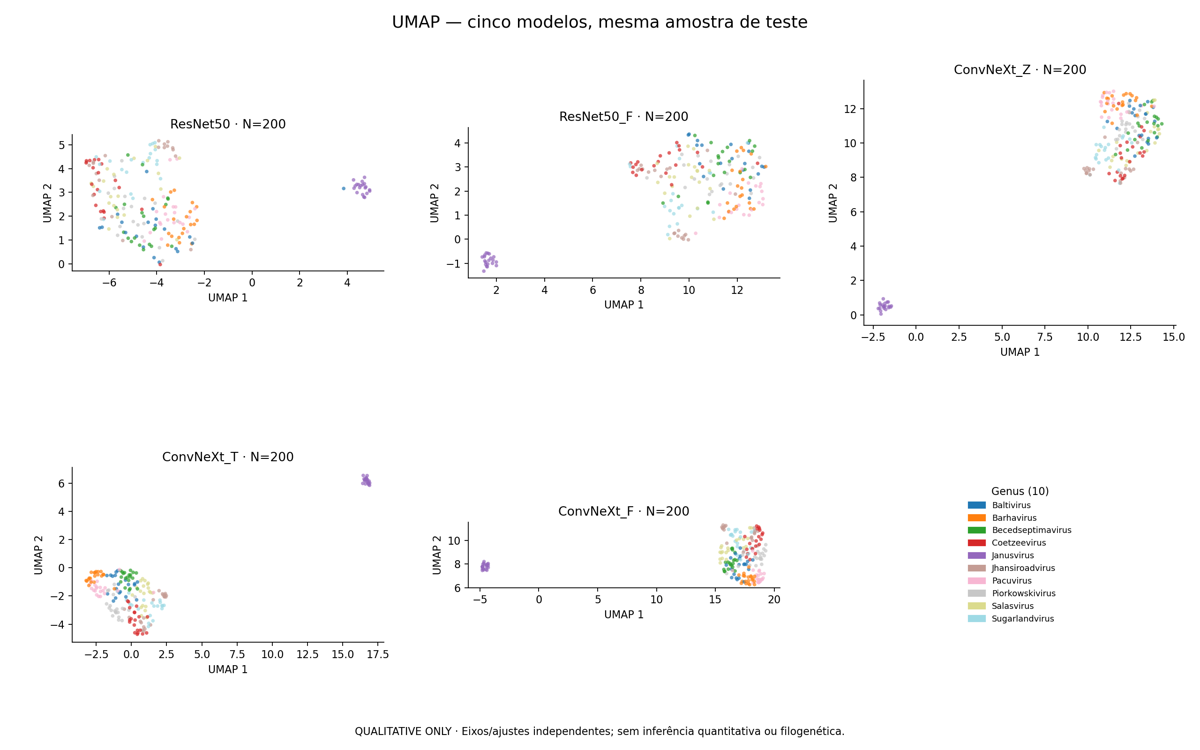

### F3 — figure_03_motifs.png

ATENÇÃO: Figura produzida com dois painéis; o C06 prevê cinco.
[LOG_PATH] Preview de: /home/mlima/workspace/cnn_metagenome/notebooks/reproduction/short/results_reproduction/motifs/figure_03_motifs.png
Origem: reprodução: short | tamanho: 401,407 bytes
Manifesto candidato: /home/mlima/workspace/cnn_metagenome/notebooks/reproduction/short/results_reproduction/motifs/manifest_07_motifs.json
  protocolo: ? | status: ? | smoke: ?
Dimensões originais: (4154, 1773)


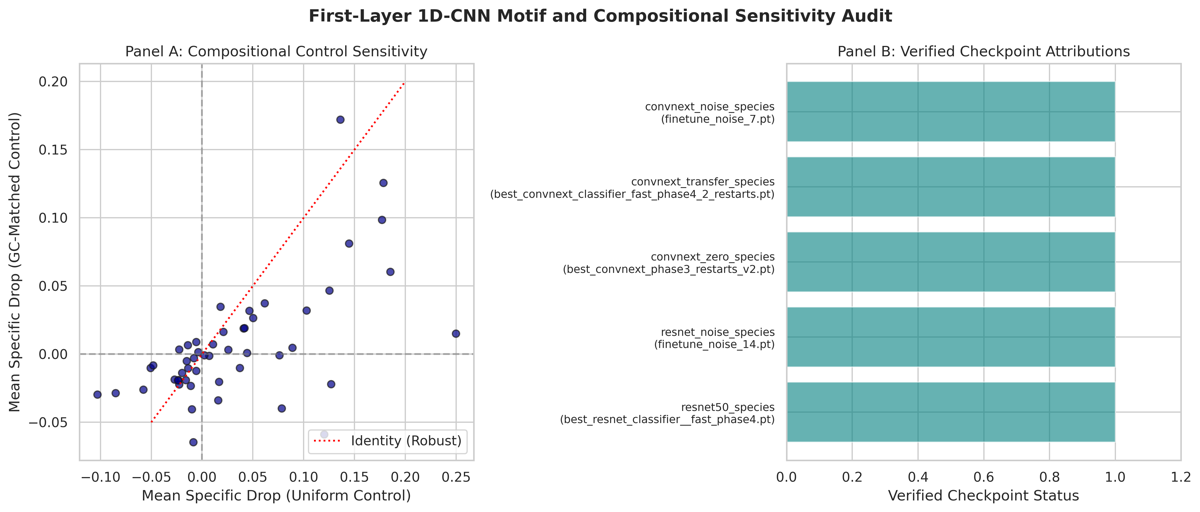

### F4 — figure_04_rscu_profile.png

ATENÇÃO: Perfil exploratório; conferir legenda e quadro de leitura.
[LOG_PATH] Preview de: /home/mlima/workspace/cnn_metagenome/notebooks/reproduction/short/results_reproduction/motifs/figure_04_rscu_profile.png
Origem: reprodução: short | tamanho: 143,219 bytes
Manifesto candidato: /home/mlima/workspace/cnn_metagenome/notebooks/reproduction/short/results_reproduction/motifs/manifest_08_triplets.json
  protocolo: ? | status: ? | smoke: ?
Dimensões originais: (3600, 1200)


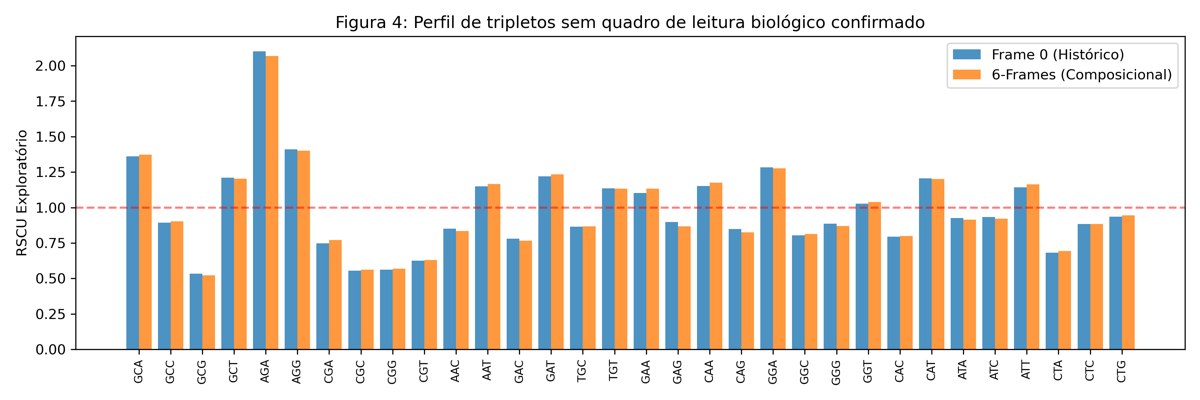

### F5 — figure_05_cooccurrence_synergy.png

ATENÇÃO: Figura produzida em barras; o C06 prevê rede.
[LOG_PATH] Preview de: /home/mlima/workspace/cnn_metagenome/notebooks/reproduction/short/results_reproduction/motifs/figure_05_cooccurrence_synergy.png
Origem: reprodução: short | tamanho: 97,256 bytes
Manifesto candidato: /home/mlima/workspace/cnn_metagenome/notebooks/reproduction/short/results_reproduction/motifs/manifest_08_triplets.json
  protocolo: ? | status: ? | smoke: ?
Dimensões originais: (1800, 1500)


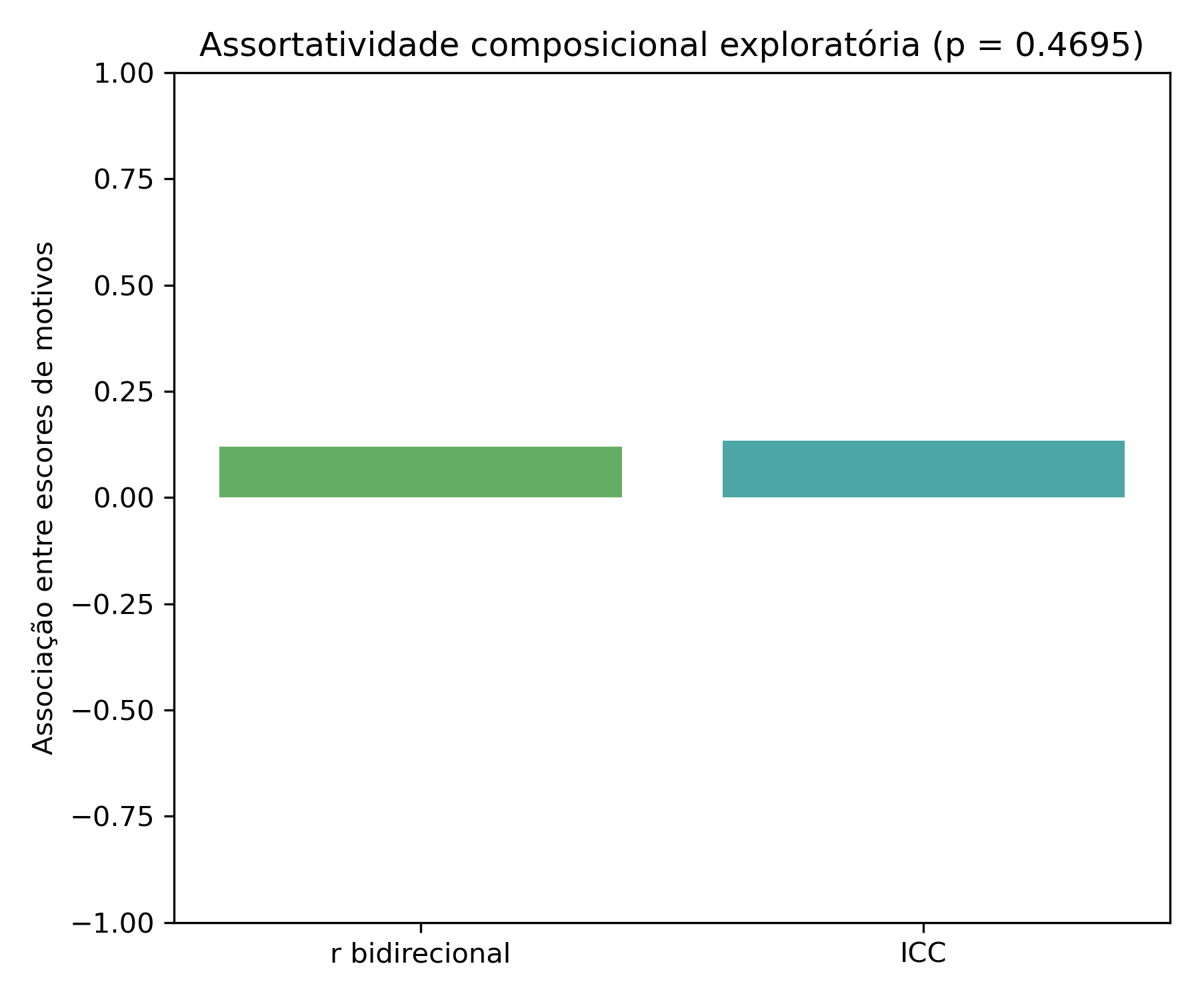

In [7]:
# Visão estática para exportação do notebook como PDF: não depende do seletor.
# Nomes representam saídas dos notebooks. T1/T3/F1 referem-se a dados-fonte,
# não às tabelas/figura finais. T11 NÃO corresponde à correlação entre arquiteturas.
NOMES_POR_ITEM = {
    "T1": "benchmark_clean_noise_summary.csv",
    "T2": "table2_profiling.csv",
    "T3": "benchmark_clean_noise_summary.csv",
    "T4": "table4_f1_bands.csv",
    "T5": "table5_latent_clustering_metrics.csv",
    "T6": "table6_taxonomic_rank_correlations.csv",
    "T7": "table7_hierarchical_entropy.csv",
    "T8": "table_08_motif_perturbation.csv",
    "T9": "table_09_exploratory_rscu.csv",
    "T10": "table_10_translation_boundary_signals.csv",
    "T11": "table_11_cooccurrence_synergy.csv",
    "T12": "table_12_long_voter_comparison.csv",
    "F1": "benchmark_clean_noise_summary.csv",  # dados para nova figura; não PNG pronto
    "F2": "umap_comparison.png",
    "F3": "figure_03_motifs.png",
    "F4": "figure_04_rscu_profile.png",
    "F5": "figure_05_cooccurrence_synergy.png",
}
AVISOS = {
    "T1": "Dados-fonte; confirmar quais modelos e classes entram na tabela.",
    "T3": "Dados-fonte; confirmar taxa de ruído, protocolo e denominador.",
    "T10": "A saída é de sinais ATG/STOP; conciliar com a definição no C06.",
    "T11": "A saída é coocorrência; NÃO comprova correlação entre arquiteturas.",
    "T12": "Conferir proveniência das sequências longas e o diagnóstico inconclusivo.",
    "F1": "Dados-fonte, não figura de robustez já renderizada.",
    "F2": "UMAP qualitativo; conferir parâmetros e IDs amostrados.",
    "F3": "Figura produzida com dois painéis; o C06 prevê cinco.",
    "F4": "Perfil exploratório; conferir legenda e quadro de leitura.",
    "F5": "Figura produzida em barras; o C06 prevê rede.",
}

from IPython.display import display, Markdown
escolhas = []
for item, filename in NOMES_POR_ITEM.items():
    subset = catalogo[(catalogo["origem"].str.startswith("reprodução:")) &
                      (catalogo["arquivo"].str.rsplit("/", n=1).str[-1] == filename)]
    if subset.empty:
        escolhas.append({"item": item, "versões": 0, "índice": None, "arquivo_mais_recente": "NÃO LOCALIZADO",
                         "modificado_utc": "", "manifestos": 0, "atenção": AVISOS.get(item, "")})
        continue
    row = subset.iloc[0]  # catálogo ordenado por data decrescente
    escolhas.append({"item": item, "versões": len(subset), "índice": int(subset.index[0]),
                     "arquivo_mais_recente": row["arquivo"], "modificado_utc": row["modificado_utc"],
                     "manifestos": row["manifestos_candidatos"], "atenção": AVISOS.get(item, "")})

resumo_revisao = pd.DataFrame(escolhas).set_index("item")
display(Markdown("## Candidatos mais recentes por saída de notebook"))
display(resumo_revisao)
print("A ordenação usa a data do arquivo. Verifique manifesto e protocolo antes de selecionar para o artigo.")

vistos = set()
for item, row in resumo_revisao.iterrows():
    display(Markdown(f"### {item} — {NOMES_POR_ITEM[item]}"))
    if row["atenção"]:
        print("ATENÇÃO:", row["atenção"])
    if pd.isna(row["índice"]):
        print("Saída ausente das pastas examinadas.")
    elif row["arquivo_mais_recente"] in vistos:
        print("Prévia já mostrada acima:", row["arquivo_mais_recente"])
    else:
        vistos.add(row["arquivo_mais_recente"])
        visualizar(int(row["índice"]), nrows=6)


## Como usar na revisão

- A versão mais recente é a **preferência inicial entre execuções do mesmo resultado**;
  `ultimas_versoes(nome)` mostra a ordem. Uma cópia pode mudar a data do arquivo.
  Compare o manifesto e o protocolo antes de decidir.
- `modo_declarado = ?` indica ausência de declaração no manifesto vinculado; `False`
  sozinho não comprova proveniência completa.
- O catálogo não acessa o servidor remoto por conta própria: execute-o no JupyterLab
  que tem os diretórios `results_reproduction` e `paper` a revisar.
- A presença de T/F no nome é apenas uma dica. A seleção final para o C06 precisa
  de definição científica, denominador, entradas, hashes e manifesto adequado.
